scp -r /Users/svenjamenzenbach/Documents/Uni/Master_Thesis/VOC2007/horse/horse_no_watermark ml-stud21@130.83.192.148:~/data/Pascal_VOC07/raw/horse_no_watermark

In [1]:
import os, sys
from PIL import Image
from tqdm import tqdm
import yaml


# Add the project root directory to sys.path
project_root = os.path.abspath('../..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_list, create_file_names_list, file_name_from_file_path
from utils import mask_on_image, dilate_mask, plot_grid

from inpainting_iopaint_lama_sdxl import inpaint_instance_iopaint_lama_sdxl
from inpainting_sdxl import setup_diffusion_model

2025-01-22 15:43:43.267939: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737560623.294946   54570 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737560623.308600   54570 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-22 15:43:43.353927: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was rena

## Datasets
### Load ISIC 2019 dataset

In [2]:
# Load the YAML file into a dictionary
dataset_yaml_file = "/workspace/home/data/datasets.yaml"
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)


# get dataset
dataset_key = "Pascal_VOC07"#ISIC2019"
dataset = datasets[dataset_key]

## Setup images, custom vocabulary and models

In [3]:
def convert_img_id(img_id, datset_name):
    if datset_name == "ISIC2019":
        # 55292 -> ISIC_0055292.jpg
        # 10 -> ISIC_0000010.jpg
        return f"ISIC_{str(img_id).zfill(7)}.jpg"
    elif datset_name == "Pascal_VOC07":
        # 27 -> 000027.jpg
        # 10 -> 000010.jpg
        return f"{str(img_id).zfill(6)}.jpg"
mask_ids = [604, 712, 592, 610, 932, 9040, 600]

In [4]:
n = 20
segmentation_id = 'pascal_test'#'gt'
images_path = dataset["raw_path"]
#segmentation_masks_path = dataset['gt_seg_path']
segmentation_masks_path = f"/workspace/home/pipeline_outputs/{dataset_key}/{segmentation_id}/seg"
mask_names = create_file_names_list(segmentation_masks_path, ignore_copy=True)[:n]
#mask_names = [convert_img_id(mask_id, dataset_key) for mask_id in mask_ids]
print(mask_names)
images = get_images_from_list(mask_names, images_path, sub_dir=True)
segmentation_masks = get_images_from_list(mask_names, segmentation_masks_path, sub_dir=True)
prompt = ""
#"part of skin in homogenous skin color"
# "remove the colorful patch and replace with skin tissue"

# For dilating the mask
kernel_size = 5
iterations = 4

pipe, generator = setup_diffusion_model(device = 0)


['000010.jpg', '000022.jpg', '000056.jpg', '000237.jpg', '000248.jpg', '000267.jpg', '000319.jpg', '000330.jpg', '000356.jpg', '000378.jpg', '000392.jpg', '000393.jpg', '000410.jpg', '000412.jpg', '000413.jpg', '000434.jpg', '000445.jpg', '000455.jpg', '000604.jpg', '000616.jpg']


/usr/local/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


## Run model on segmentations and visualize the inpainting

  0%|          | 0/20 [00:00<?, ?it/s]2025-01-22 15:44:01.692 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cuda.amp.a

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:01


  0%|          | 0/24 [00:00<?, ?it/s]

Image: 000010.jpg


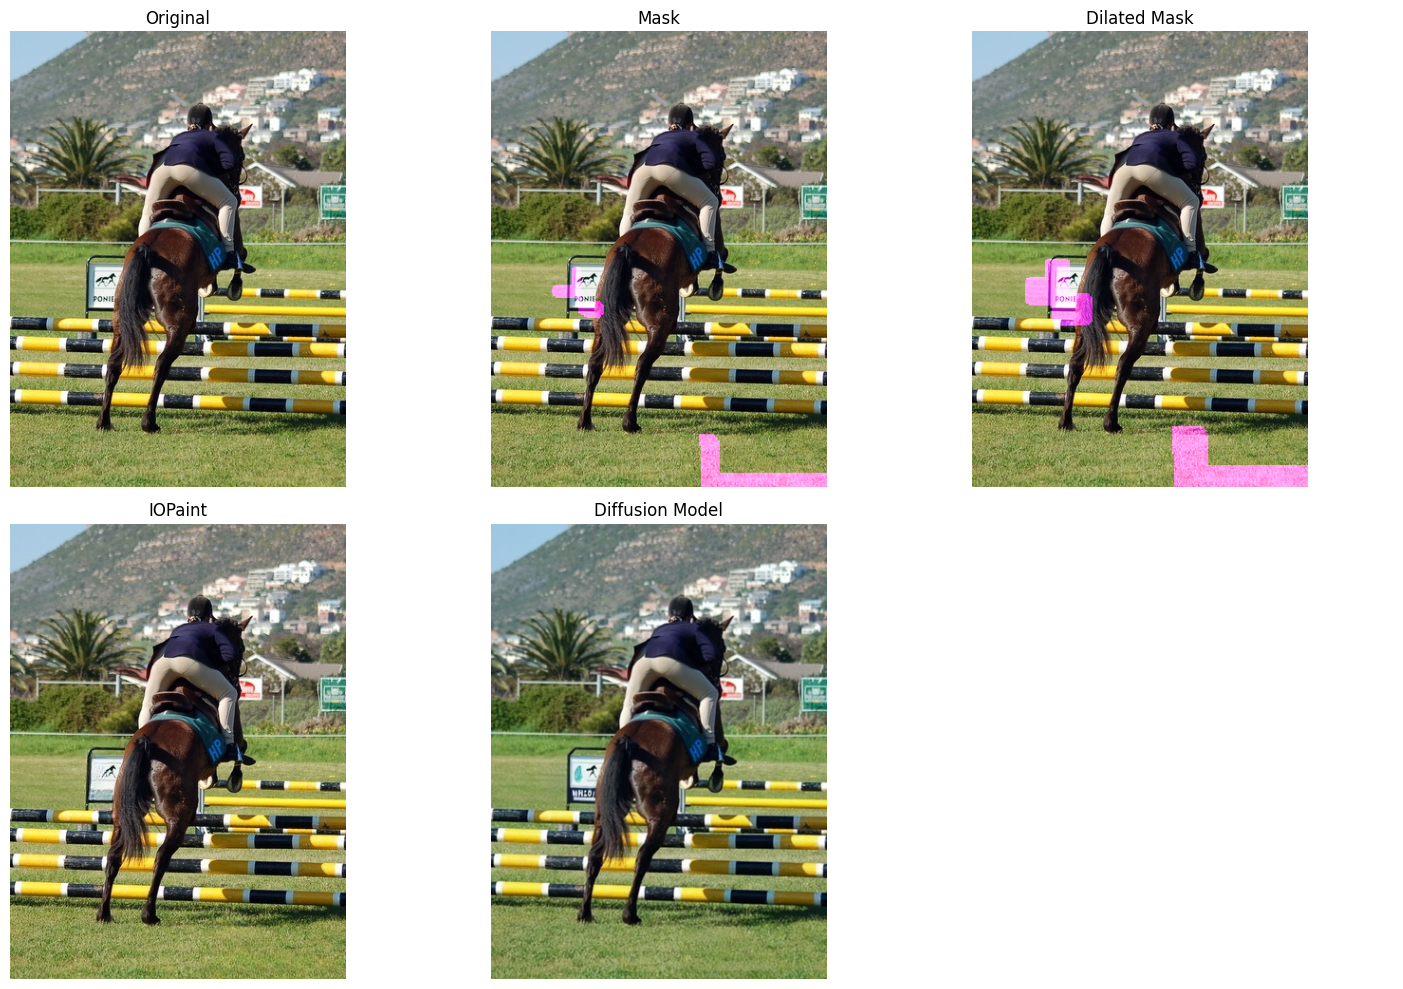

  5%|▌         | 1/20 [00:20<06:32, 20.67s/it]2025-01-22 15:44:22.204 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
  5%|▌         | 1/20 [00:25<08:11, 25.85s/it]


KeyboardInterrupt: 

In [5]:
kernel_size = 5
iterations = 4
output_dir = f"/workspace/home/pipeline_outputs/{dataset_key}"
save_dir = f"{output_dir}/{segmentation_id}"

for i, mask_path in enumerate(tqdm(segmentation_masks)):
    # result 1: inpaint with iopaint
    # result 2: inpaint diffusion model with result 1 as input

    image_path = images[i]
    
    result1, result2 = inpaint_instance_iopaint_lama_sdxl(
        mask_path,
        image_path,
        prompt,
        pipe,
        generator,
        kernel_size=kernel_size,
        iterations=iterations,
    )

    mask_file_name = file_name_from_file_path(mask_path)

    # visualize output
    print(f"Image: {mask_file_name}")
    img = Image.open(image_path) 
    mask = Image.open(mask_path).convert("L").point(lambda x: 255 if x > 128 else 0)
    dilated_mask = dilate_mask(mask, kernel_size=kernel_size, iterations=iterations)
    mask = mask.resize(img.size)
    dilated_mask = dilated_mask.resize(img.size)
    mask_on_img = mask_on_image(img, mask)
    dilated_mask_on_img = mask_on_image(img, dilated_mask)
    plot_grid([img, mask_on_img, dilated_mask_on_img, result1, result2], label=["Original", "Mask", "Dilated Mask", "IOPaint", "Diffusion Model"], ncols=3)
    result1.resize((400,400)).save(f"{save_dir}/lama_{mask_file_name.replace('.jpg', '.png')}")
    result2.resize((400,400)).save(f"{save_dir}/sdxl_{mask_file_name.replace('.jpg', '.png')}")
    dilated_mask_on_img.resize((400,400)).save(f"{save_dir}/dilated_mask_{segmentation_id}_{mask_file_name}")